<a href="https://colab.research.google.com/github/aneesadeyas/curiosity-cup-2026-labour-productivity/blob/main/SIT3020_Assignment_Group_D_Finalized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIT3020 — Group Assignment
## Churn Telco Data Analysis
**Universiti Malaya | Group D | Semestester II | Session 2025/2026**

---

### Dataset: `Churn Telco.csv`

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

---
## Phase 1 — Loading & Inspecting

### 1.1 Load the Dataset


In [ ]:
# Load the Churn_Telco Dataset

Telco = pd.read_csv("Churn_Telco.csv")
print(f"Shape: {Telco.shape}")
print(f"Columns: {Telco.columns.tolist()}\n")
display(Telco.dtypes)
print("\nSummary of the dataset:\n")
display(Telco.describe().round(2))

Shape: (10000, 14)
Columns: ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']



,0
RowNumber,int64
CustomerId,int64
Surname,object
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64



Summary of the dataset:



,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


### 1.2 Inspect the Mess

Before cleaning anything, understand what problems exist.


In [ ]:
# Missing value from the Churn_Telco dataset
print("Missing values:")
missing = pd.DataFrame({
    "count": Telco.isnull().sum(),
    "pct(%)": (Telco.isnull().mean()*100).round(2)
})

if missing["count"].sum() == 0:
    print("No missing values found.")
else:
    print(missing[missing["count"]>0])

# Duplicates row
print("\nDuplicate rows:")
if Telco.duplicated().sum() == 0:
    print("No duplicate rows found.")
else:
    print(f"Duplicate rows: {Telco.duplicated().sum()} row(s)")

# Features with negative values
print("\nFeatures with negative values:")
negative_values = {}
for col in Telco.columns:
    if pd.api.types.is_numeric_dtype(Telco[col]):
        neg_count = (Telco[col] < 0).sum()
        if neg_count > 0:
            negative_values[col] = neg_count

if negative_values:
    for col, count in negative_values.items():
        print(f"{col}: {count} negative value(s)")
else:
    print("No negative values found in any column.")



Missing values:
No missing values found.

Duplicate rows:
No duplicate rows found.

Features with negative values:
No negative values found in any column.


---
## Phase 2 – Outliers Management

### 2.1 Outliers Detection

In [ ]:
# IQR Method to detect outliers in the columns CreditScore, Age, Balance and EstimatedSalary
outlier_data = {}

for column in ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']:
    Q1 = Telco[column].quantile(0.25)
    Q3 = Telco[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = Telco[(Telco[column] < lower_bound) | (Telco[column] > upper_bound)]
    outlier_data[column] = outliers
    print(f"Number of outliers in {column:20}: {len(outliers)} row(s)")

Number of outliers in CreditScore         : 15 row(s)
Number of outliers in Age                 : 359 row(s)
Number of outliers in Balance             : 0 row(s)
Number of outliers in EstimatedSalary     : 0 row(s)


### 2.2 Handling Outliers

In [ ]:
Telco_Clean = Telco.copy()

# Check imbalance in the Exited column
print("\nValue counts for the Exited column:")
print(Telco_Clean["Exited"].value_counts())
print("\nPercentage distribution for the Exited column ––")
print(f"Percentage of customers who exited : {(Telco_Clean['Exited'].mean() * 100):.2f}%")
print(f"Percentage of customers who stayed : {(1 - Telco_Clean['Exited'].mean()) * 100:.2f}%")


Value counts for the Exited column:
Exited
0    7963
1    2037
Name: count, dtype: int64

Percentage distribution for the Exited column ––
Percentage of customers who exited : 20.37%
Percentage of customers who stayed : 79.63%


Comment:

The target variable Exited shows a clear class imbalance with a ratio of approximately 4:1. While the majority of customers (79.63%) remain with the Telco Company, the minority class (20.37%) represents the critical 'churn' segment. In predictive modeling, this imbalance suggests that Accuracy may be a misleading metric, as a model could achieve ~80% accuracy by simply predicting that no one ever leaves. Therefore, Phase 4 evaluation should prioritize Recall and F1-Score to ensure churners are correctly identified.

In [ ]:
# Index of outliers in the CreditScore column
outlier_indices_CreditScore = outlier_data['CreditScore'].index

# Outlier dataframe from the CreditScore column
print("\nOutliers rows from the CreditScore column:")
display(outlier_data["CreditScore"])

# Delete the outliers from the CreditScore column
Telco_Clean = Telco_Clean.drop(outlier_indices_CreditScore)

print(f"\nShape of the dataset before removing outliers: {Telco.shape}")
print(f"Shape of the dataset after removing outliers: {Telco_Clean.shape}")
display(Telco_Clean.head(10))


Outliers rows from the CreditScore column:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
942,943,15804586,Lin,376,France,Female,46,6,0.00,1,1,0,157333.69,1
1193,1194,15779947,Thomas,363,Spain,Female,28,6,146098.43,3,1,0,100615.14,1
1405,1406,15612494,Panicucci,359,France,Female,44,6,128747.69,1,1,0,146955.71,1
1631,1632,15685372,Azubuike,350,Spain,Male,54,1,152677.48,1,1,1,191973.49,1
1838,1839,15758813,Campbell,350,Germany,Male,39,0,109733.20,2,0,0,123602.11,1
1962,1963,15692416,Aikenhead,358,Spain,Female,52,8,143542.36,3,1,0,141959.11,1
2473,2474,15679249,Chou,351,Germany,Female,57,4,163146.46,1,1,0,169621.69,1
2579,2580,15597896,Ozoemena,365,Germany,Male,30,0,127760.07,1,1,0,81537.85,1
8154,8155,15791533,Ch'ien,367,Spain,Male,42,6,93608.28,1,1,0,168816.73,1



Shape of the dataset before removing outliers: (10000, 14)
Shape of the dataset after removing outliers: (9985, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0
10,11,15767821,Bearce,528,France,Male,31,6,102016.72,2,0,0,80181.12,0


We delete outliers from CreditScore column because removing outliers from this column will help improve the performance of our predictive models. Outliers can skew the distribution of data and lead to inaccurate predictions, especially in models that are sensitive to extreme values. By removing outliers, we can ensure that our models are trained on more representative data, which can enhance their ability to generalize and make accurate predictions on new, unseen data.

In [ ]:
# Index of outliers in the Age column
outlier_indices_Age = outlier_data['Age'].index

# Intersection of outlier indices for CreditScore and Age columns
intersection_indices = set(outlier_indices_CreditScore).intersection(set(outlier_indices_Age))
print(intersection_indices)

# Outlier dataframe from the Age column
print("\nOutliers rows from the Age column:")
display(outlier_data["Age"])

# Association between Age and Exited columns using the Mann-Whitney U Test
age_churn = Telco_Clean[["Age", "Exited"]]
group_churned = age_churn[age_churn["Exited"] == 1]["Age"]
group_not_churned = age_churn[age_churn["Exited"] == 0]["Age"]
u_statistic, p_value = stats.mannwhitneyu(group_churned, group_not_churned, alternative='two-sided')
print(f"\nMann-Whitney U Test Results ––")
print(f"{'U Statistic':<15}: {u_statistic:.4f}")
print(f"{'P-value':<15}: {p_value:.4e}")
if p_value < 0.05:
    print("\nThere is a significant difference in Age between churned and non-churned customers (reject null hypothesis).")
    print("We should not remove the Age outliers as they may contain important information about the relationship between Age and customer churn.")
else:
    print("\nThere is no significant difference in Age between churned and non-churned customers (fail to reject null hypothesis).")
    print("We can simply ignore and drop the Age features.")

# Cap the Age outliers by replacing with the fence value
Q1_Age = Telco['Age'].quantile(0.25)
Q3_Age = Telco['Age'].quantile(0.75)
IQR_Age = Q3_Age - Q1_Age
lower_bound_Age = Q1_Age - 1.5 * IQR_Age
upper_bound_Age = Q3_Age + 1.5 * IQR_Age

print(f"\nLower bound for Age: {lower_bound_Age:.2f}")
print(f"Upper bound for Age: {upper_bound_Age:.2f}")

# Replacing outliers in the Age column with the upper and lower bound values
Telco_Clean['Age'] = np.where(Telco_Clean['Age'] < lower_bound_Age, lower_bound_Age, Telco_Clean['Age'])
Telco_Clean['Age'] = np.where(Telco_Clean['Age'] > upper_bound_Age, upper_bound_Age, Telco_Clean['Age'])

print("\nCleaned outliers rows from the Age column:")
display(Telco_Clean.loc[outlier_indices_Age])

# Resetting the index after dropping rows
Telco_Clean = Telco_Clean.reset_index(drop=True)
print("\nIndex reset for the cleaned dataset.")

set()

Outliers rows from the Age column:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
58,59,15623944,T'ien,511,Spain,Female,66,4,0.00,1,1,0,1643.11,1
85,86,15805254,Ndukaku,652,Spain,Female,75,10,0.00,2,1,1,114675.75,0
104,105,15804919,Dunbabin,670,Spain,Female,65,1,0.00,1,1,1,177655.68,1
158,159,15589975,Maclean,646,France,Female,73,6,97259.25,1,0,1,104719.66,0
181,182,15789669,Hsia,510,France,Male,65,2,0.00,2,1,1,48071.61,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9753,9754,15705174,Chiedozie,656,Germany,Male,68,7,153545.11,1,1,1,186574.68,0
9765,9766,15777067,Thomas,445,France,Male,64,2,136770.67,1,0,1,43678.06,0
9832,9833,15814690,Chukwujekwu,595,Germany,Female,64,2,105736.32,1,1,1,89935.73,1
9894,9895,15704795,Vagin,521,France,Female,77,6,0.00,2,1,1,49054.10,0



Mann-Whitney U Test Results ––
U Statistic    : 11792883.5000
P-value        : 1.4332e-229

There is a significant difference in Age between churned and non-churned customers (reject null hypothesis).
We should not remove the Age outliers as they may contain important information about the relationship between Age and customer churn.

Lower bound for Age: 14.00
Upper bound for Age: 62.00

Cleaned outliers rows from the Age column:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
58,59,15623944,T'ien,511,Spain,Female,62.0,4,0.00,1,1,0,1643.11,1
85,86,15805254,Ndukaku,652,Spain,Female,62.0,10,0.00,2,1,1,114675.75,0
104,105,15804919,Dunbabin,670,Spain,Female,62.0,1,0.00,1,1,1,177655.68,1
158,159,15589975,Maclean,646,France,Female,62.0,6,97259.25,1,0,1,104719.66,0
181,182,15789669,Hsia,510,France,Male,62.0,2,0.00,2,1,1,48071.61,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9753,9754,15705174,Chiedozie,656,Germany,Male,62.0,7,153545.11,1,1,1,186574.68,0
9765,9766,15777067,Thomas,445,France,Male,62.0,2,136770.67,1,0,1,43678.06,0
9832,9833,15814690,Chukwujekwu,595,Germany,Female,62.0,2,105736.32,1,1,1,89935.73,1
9894,9895,15704795,Vagin,521,France,Female,62.0,6,0.00,2,1,1,49054.10,0



Index reset for the cleaned dataset.


---
## Phase 3 – Feature Transformation

### 3.1 Drop and Encode

In [ ]:
# Drop Unessential Columns
Telco_Clean = Telco_Clean.drop(columns=["RowNumber", "CustomerId", "Surname"])
print(f"Shape: {Telco_Clean.shape}")
print(f"Columns: {Telco_Clean.columns.tolist()}\n")
print("Data types after dropping unessential columns:")
print(Telco_Clean.dtypes)

Shape: (9985, 11)
Columns: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Data types after dropping unessential columns:
CreditScore          int64
Geography           object
Gender              object
Age                float64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [ ]:
# Checking unique values of categorical variables
print("\nUnique values of categorical variables:")
for col in ["Geography","Gender"]:
    print(f"{col}: {Telco_Clean[col].unique()}")

print("\nDisplayed dataset structure before encoding:")
display(Telco_Clean.head(6))

# Encoding Categorical Variables – One-Hot Encoding of Geography
Telco_Clean = pd.get_dummies(
    Telco_Clean,
    columns=["Gender","Geography"], # (France is the 'baseline' represented when both are 0 for Geography feature)
    drop_first=True,
    dtype=int
)

# Checking data types after encoding
print("\nData types after encoding:")
print(Telco_Clean.dtypes)
print("\nDisplayed dataset structure after encoding:")
display(Telco_Clean.head(6))


Unique values of categorical variables:
Geography: ['France' 'Spain' 'Germany']
Gender: ['Female' 'Male']

Displayed dataset structure before encoding:


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42.0,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41.0,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42.0,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39.0,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43.0,2,125510.82,1,1,1,79084.10,0
5,645,Spain,Male,44.0,8,113755.78,2,1,0,149756.71,1



Data types after encoding:
CreditScore            int64
Age                  float64
Tenure                 int64
Balance              float64
NumOfProducts          int64
HasCrCard              int64
IsActiveMember         int64
EstimatedSalary      float64
Exited                 int64
Gender_Male            int64
Geography_Germany      int64
Geography_Spain        int64
dtype: object

Displayed dataset structure after encoding:


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Gender_Male,Geography_Germany,Geography_Spain
0,619,42.0,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41.0,1,83807.86,1,0,1,112542.58,0,0,0,1
2,502,42.0,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39.0,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43.0,2,125510.82,1,1,1,79084.10,0,0,0,1
5,645,44.0,8,113755.78,2,1,0,149756.71,1,1,0,1


### 3.2 Skewness Check

In [ ]:
# Skewness of the columns CreditScore, Age, Balance, and EstimatedSalary
print("\nSkewness of the columns CreditScore, Age, Balance, and EstimatedSalary before transformation ––")
for col in ["CreditScore", "Age", "Balance", "EstimatedSalary"]:
    skewness = Telco[col].skew()
    print(f" - Skewness of {col:<20}: {skewness:.2f}")

print("\nSkewness of the columns CreditScore, Age, Balance, and EstimatedSalary after transformation ––")
for col in ["CreditScore", "Age", "Balance", "EstimatedSalary"]:
    skewness = Telco_Clean[col].skew()
    print(f" - Skewness of {col:<20}: {skewness:.2f}")



Skewness of the columns CreditScore, Age, Balance, and EstimatedSalary before transformation ––
 - Skewness of CreditScore         : -0.07
 - Skewness of Age                 : 1.01
 - Skewness of Balance             : -0.14
 - Skewness of EstimatedSalary     : 0.00

Skewness of the columns CreditScore, Age, Balance, and EstimatedSalary after transformation ––
 - Skewness of CreditScore         : -0.05
 - Skewness of Age                 : 0.63
 - Skewness of Balance             : -0.14
 - Skewness of EstimatedSalary     : 0.00


Comment:

1. The CreditScore was already nearly symmetrical. By removing the 15 extreme outliers on the low end, it pulled the distribution even closer to a perfect zero. This is a highly stable feature. No further action (like log transformation) is needed.

2. The model will now be much more balanced and won't be overly distracted by extreme senior ages. It is now safe for training.

3. The Balance column shows a skewness of -0.14, indicating a fairly symmetrical distribution. As the value falls well within the -0.5 to 0.5 range, the data is approximately normal. Consequently, no non-linear transformations were required, and standard scaling was sufficient for feature normalization.

4. The skewness value of EstimatedSalary column is 0.00 indicates a very perfect symmetrical distribution. However, scaling is still needed because the numbers are large.

### 3.3 Adding New Features

In [ ]:
zero_salary_count = (Telco_Clean["EstimatedSalary"] == 0).sum()
negative_salary_count = (Telco_Clean["EstimatedSalary"] < 0).sum()

if zero_salary_count > 0 or negative_salary_count > 0:
    print(f"Warning: Found {zero_salary_count} zero salaries and {negative_salary_count} negative salaries.")

# Balance-to-Salary Ratio
Telco_Clean["BalanceSalaryRatio"] = np.where(
    Telco_Clean["EstimatedSalary"] > 0,
    Telco_Clean["Balance"] / Telco_Clean["EstimatedSalary"],
    0
)

print("\nBalance-to-Salary Ratio added to the dataset:")
display(Telco_Clean[["Balance", "EstimatedSalary", "BalanceSalaryRatio"]].head(10))

negative_tenure_count = (Telco_Clean["Tenure"] < 0).sum()
if negative_tenure_count > 0:
    print(f"Warning: Found {negative_tenure_count} negative tenure values.")

# Products per Tenure
Telco_Clean["ProductsPerTenure"] = np.where(
    Telco_Clean["Tenure"] >= 0,
    Telco_Clean["NumOfProducts"] / (Telco_Clean["Tenure"] + 1),
    0
)

print("\nProducts per Tenure added to the dataset:")
display(Telco_Clean[["NumOfProducts", "Tenure", "ProductsPerTenure"]].head(10))


Telco_Clean.to_csv("Churn_Telco_Clean.csv", index=False)
print("\nCleaned dataset saved as 'Churn_Telco_Clean.csv'")

print("\nColumns in the cleaned dataset:")
Telco_Clean.columns.tolist()


Balance-to-Salary Ratio added to the dataset:


,Balance,EstimatedSalary,BalanceSalaryRatio
0,0.00,101348.88,0.000000
1,83807.86,112542.58,0.744677
2,159660.80,113931.57,1.401375
3,0.00,93826.63,0.000000
4,125510.82,79084.10,1.587055
5,113755.78,149756.71,0.759604
6,0.00,10062.80,0.000000
7,142051.07,74940.50,1.895518
8,134603.88,71725.73,1.876647
9,102016.72,80181.12,1.272328



Products per Tenure added to the dataset:


,NumOfProducts,Tenure,ProductsPerTenure
0,1,2,0.333333
1,1,1,0.500000
2,3,8,0.333333
3,2,1,1.000000
4,1,2,0.333333
5,2,8,0.222222
6,2,7,0.250000
7,2,4,0.400000
8,1,2,0.333333
9,2,6,0.285714



Cleaned dataset saved as 'Churn_Telco_Clean.csv'

Columns in the cleaned dataset:


['CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited',
 'Gender_Male',
 'Geography_Germany',
 'Geography_Spain',
 'BalanceSalaryRatio',
 'ProductsPerTenure',
 'Geography']

In [ ]:
print(Telco_Clean.shape)

(9985, 14)


---
## Phase 4 – Data Splitting

In [ ]:
%matplotlib inline
from sklearn.model_selection import train_test_split

In [ ]:
Telco_Clean = pd.read_csv("Churn_Telco_Clean.csv")
print(f"Shape: {Telco_Clean.shape}")
print(f"Columns: {Telco_Clean.columns.tolist()}\n")
display(Telco_Clean.dtypes)
print("\nSummary of the dataset:\n")
display(Telco_Clean.describe().round(2))

Shape: (9985, 14)
Columns: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Gender_Male', 'Geography_Germany', 'Geography_Spain', 'BalanceSalaryRatio', 'ProductsPerTenure']



,0
CreditScore,int64
Age,float64
Tenure,int64
Balance,float64
NumOfProducts,int64
HasCrCard,int64
IsActiveMember,int64
EstimatedSalary,float64
Exited,int64
Gender_Male,int64



Summary of the dataset:



,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Gender_Male,Geography_Germany,Geography_Spain,BalanceSalaryRatio,ProductsPerTenure
count,9985.00,9985.00,9985.00,9985.00,9985.00,9985.00,9985.00,9985.00,9985.0,9985.00,9985.00,9985.00,9985.00,9985.00
mean,650.96,38.65,5.01,76471.45,1.53,0.71,0.52,100033.19,0.2,0.55,0.25,0.25,3.88,0.37
std,96.07,9.75,2.89,62395.04,0.58,0.46,0.50,57519.38,0.4,0.50,0.43,0.43,108.42,0.34
min,383.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0,0.00,0.00,0.00,0.00,0.09
25%,584.00,32.00,3.00,0.00,1.00,0.00,0.00,50908.48,0.0,0.00,0.00,0.00,0.00,0.17
50%,652.00,37.00,5.00,97157.96,1.00,1.00,1.00,100127.71,0.0,1.00,0.00,0.00,0.75,0.25
75%,718.00,44.00,8.00,127637.92,2.00,1.00,1.00,149370.93,0.0,1.00,1.00,0.00,1.52,0.50
max,850.00,62.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0,1.00,1.00,1.00,10614.66,3.00


In [ ]:
X = Telco_Clean[['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
                'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Gender_Male',
                'Geography_Germany', 'Geography_Spain', 'BalanceSalaryRatio',
                'ProductsPerTenure']]
y = Telco_Clean['Exited']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.8,
    stratify=y,
    random_state=42
    )

print('Telco_Churn split:\n')
print(f'  Train: {X_train.shape}  |  Test: {X_test.shape}')
print(f'  Train Exited: {y_train.mean():.3f}')
print(f'  Test  Exited: {y_test.mean():.3f}')

Telco_Churn split:

  Train: (7988, 13)  |  Test: (1997, 13)
  Train Exited: 0.203
  Test  Exited: 0.202


A dataset of 10,000 rows is a great size. By keeping 80% (7,988 rows) for training, we are giving our machine learning model a massive guide with thousands of examples to learn the exact patterns of why customers leave.

---
## Phase 5 – Transformer for Scaling Purpose

In [ ]:
# Checking the skewness of the target variable and the features
print("\nSkewness of the columns Age, CreditScore, Balance, EstimatedSalary, BalanceSalaryRatio, ProductsPerTenure ––")
for col in ["CreditScore", "Age", "Balance", "EstimatedSalary", "BalanceSalaryRatio", "ProductsPerTenure"]:
    skewness = Telco_Clean[col].skew()
    print(f" - Skewness of {col:<20}: {skewness:.2f}")


Skewness of the columns Age, CreditScore, Balance, EstimatedSalary, BalanceSalaryRatio, ProductsPerTenure ––
 - Skewness of CreditScore         : -0.05
 - Skewness of Age                 : 0.63
 - Skewness of Balance             : -0.14
 - Skewness of EstimatedSalary     : 0.00
 - Skewness of BalanceSalaryRatio  : 94.19
 - Skewness of ProductsPerTenure   : 2.79


In [ ]:
# Creating the transformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("standard_scaler", StandardScaler(), ["CreditScore","Balance","EstimatedSalary"]),
        ("robust_scaler", RobustScaler(), ["Age","BalanceSalaryRatio","ProductsPerTenure"]),
    ],
    remainder="passthrough"
)

---
## Phase 6 – Exploratory Data Analysis

### 6.1 Statistical Summary of Numerical Features

In [ ]:
print("Statistical Summary of Numerical Features:")
display(Telco_Clean.describe().round(2))

Statistical Summary of Numerical Features:


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Gender_Male,Geography_Germany,Geography_Spain,BalanceSalaryRatio,ProductsPerTenure
count,9985.00,9985.00,9985.00,9985.00,9985.00,9985.00,9985.00,9985.00,9985.0,9985.00,9985.00,9985.00,9985.00,9985.00
mean,650.96,38.65,5.01,76471.45,1.53,0.71,0.52,100033.19,0.2,0.55,0.25,0.25,3.88,0.37
std,96.07,9.75,2.89,62395.04,0.58,0.46,0.50,57519.38,0.4,0.50,0.43,0.43,108.42,0.34
min,383.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0,0.00,0.00,0.00,0.00,0.09
25%,584.00,32.00,3.00,0.00,1.00,0.00,0.00,50908.48,0.0,0.00,0.00,0.00,0.00,0.17
50%,652.00,37.00,5.00,97157.96,1.00,1.00,1.00,100127.71,0.0,1.00,0.00,0.00,0.75,0.25
75%,718.00,44.00,8.00,127637.92,2.00,1.00,1.00,149370.93,0.0,1.00,1.00,0.00,1.52,0.50
max,850.00,62.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0,1.00,1.00,1.00,10614.66,3.00


### 6.2 Category Distribution for Target Variable

In [ ]:
print("Distribution of Exited (Target Variable):")
print(Telco_Clean["Exited"].value_counts())

print("\nPercentage Distribution:")
print((Telco_Clean["Exited"].value_counts(normalize=True)*100).round(2))

Distribution of Exited (Target Variable):
Exited
0    7963
1    2022
Name: count, dtype: int64

Percentage Distribution:
Exited
0    79.75
1    20.25
Name: proportion, dtype: float64


### 6.3 Category Distribution for Categorical Features

In [ ]:
#churn rate by gender
gender_churn = pd.crosstab(Telco_Clean["Gender_Male"], Telco_Clean["Exited"], normalize="index")*100
print("Churn % by Gender:")
print(gender_churn.round(2))

#churn rate by geography
Telco_Clean["Geography"] = np.select(
    [
        (Telco_Clean["Geography_Germany"] == 1),
        (Telco_Clean["Geography_Spain"] == 1)
    ],
    ["Germany","Spain"],
    default="France"
)

geo_churn = pd.crosstab(Telco_Clean["Geography"], Telco_Clean["Exited"], normalize="index")*100
print("Churn % by Geography:")
print(geo_churn.round(2))

Churn % by Gender:
Exited           0      1
Gender_Male              
0            75.06  24.94
1            83.65  16.35
Churn % by Geography:
Exited         0      1
Geography              
France     83.95  16.05
Germany    67.66  32.34
Spain      83.50  16.50


### 6.4 Numerical Relationship with Target Variable

In [ ]:
num_compare = Telco_Clean.groupby("Exited")[[
    "CreditScore","Age","Tenure","Balance","NumOfProducts",
    "EstimatedSalary","BalanceSalaryRatio","ProductsPerTenure"
]].mean().round(2)

print("Average Feature Values by Churn Status:")
display(num_compare)

Average Feature Values by Churn Status:


,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,BalanceSalaryRatio,ProductsPerTenure
Exited,,,,,,,,
0,651.85,37.12,5.03,72745.30,1.54,99738.39,2.48,0.37
1,647.46,44.69,4.94,91145.71,1.47,101194.14,9.42,0.36


### 6.5 Correlation Matrix

In [ ]:
numeric_cols = [
    "CreditScore","Age","Tenure","Balance","NumOfProducts",
    "HasCrCard","IsActiveMember","EstimatedSalary",
    "BalanceSalaryRatio","ProductsPerTenure","Exited"
]

corr = Telco_Clean[numeric_cols].corr().round(2)

print("Correlation with Exited:")
print(corr["Exited"].sort_values(ascending=False))

Correlation with Exited:
Exited                1.00
Age                   0.31
Balance               0.12
BalanceSalaryRatio    0.03
EstimatedSalary       0.01
HasCrCard            -0.01
Tenure               -0.01
ProductsPerTenure    -0.01
CreditScore          -0.02
NumOfProducts        -0.05
IsActiveMember       -0.16
Name: Exited, dtype: float64


---
## Phase 7 - Visualization

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

Telco_Clean = pd.read_csv("Churn_Telco_Clean.csv")

In [ ]:
Telco_Clean["Geography"] = np.select(
    [
        (Telco_Clean["Geography_Germany"] == 1),
        (Telco_Clean["Geography_Spain"] == 1)
    ],
    ["Germany", "Spain"],
    default="France"
)

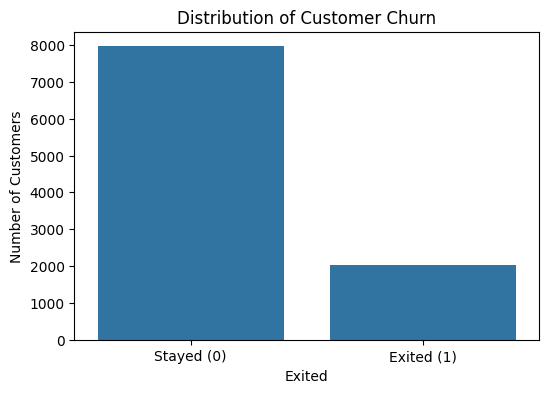

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="Exited", data=Telco_Clean)
plt.title("Distribution of Customer Churn")
plt.xticks([0,1], ["Stayed (0)", "Exited (1)"])
plt.ylabel("Number of Customers")
plt.show()

Comment: The target variable Exited exhibits a clear imbalance, with non-churned customers significantly outnumbering churned customers. Approximately four out of every five customers remained with the company, while only one out of five customers exited. This confirms that churn is a minority event and highlights the importance of carefully identifying the churn segment during predictive modeling.

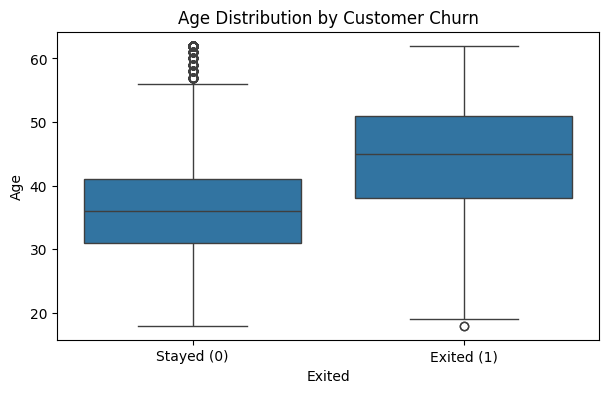

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Exited", y="Age", data=Telco_Clean)
plt.title("Age Distribution by Customer Churn")
plt.xticks([0,1], ["Stayed (0)", "Exited (1)"])
plt.show()

Comment:
Customers who exited demonstrate a noticeably higher age distribution than those who remained. The median and upper quartile ages for churned customers are visibly higher, supporting the earlier statistical finding that age has the strongest positive relationship with churn. This suggests that older customers form a particularly vulnerable churn segment.

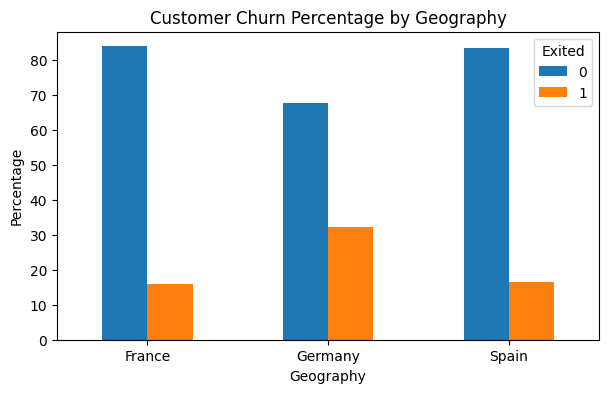

In [ ]:
geo_churn = pd.crosstab(Telco_Clean["Geography"], Telco_Clean["Exited"], normalize="index")*100
geo_churn.plot(kind="bar", figsize=(7,4))
plt.title("Customer Churn Percentage by Geography")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

Comment: Churn behavior varies across geographical regions. Customers from Germany exhibit a visibly higher proportion of churn compared to France and Spain, suggesting that location-specific service satisfaction, competition, or customer expectations may influence retention outcomes. Geography therefore appears to be an important segmentation variable in churn analysis.

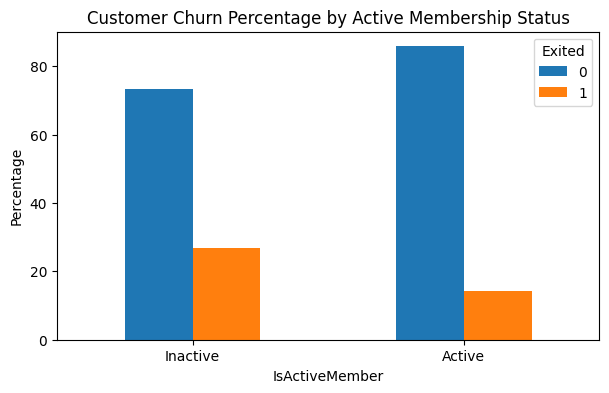

In [ ]:
active_churn = pd.crosstab(Telco_Clean["IsActiveMember"], Telco_Clean["Exited"], normalize="index")*100
active_churn.plot(kind="bar", figsize=(7,4))
plt.title("Customer Churn Percentage by Active Membership Status")
plt.ylabel("Percentage")
plt.xticks([0,1], ["Inactive", "Active"], rotation=0)
plt.show()

Comment: Active membership status demonstrates a substantial relationship with churn. Inactive customers show a considerably larger churn percentage than active members, indicating that customer engagement plays a critical role in retention. This finding suggests that improving customer activity and interaction may reduce future churn rates.

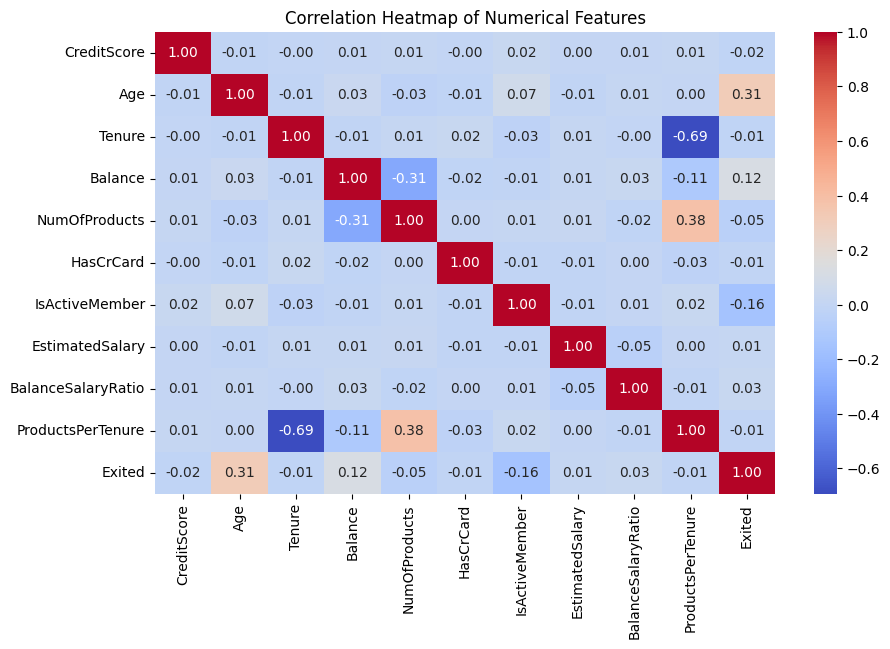

In [ ]:
numeric_cols = [
    "CreditScore","Age","Tenure","Balance","NumOfProducts",
    "HasCrCard","IsActiveMember","EstimatedSalary",
    "BalanceSalaryRatio","ProductsPerTenure","Exited"
]

plt.figure(figsize=(10,6))
sns.heatmap(Telco_Clean[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Comment: The correlation heatmap confirms that Age has the strongest positive association with churn, while IsActiveMember shows the strongest negative association. Most other variables exhibit relatively weak individual linear relationships, suggesting that customer churn may be influenced by a combination of interacting demographic, financial, and engagement-related factors rather than any single standalone feature.

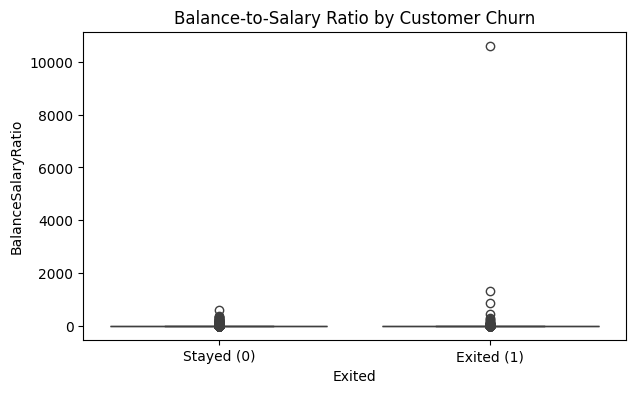

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(x="Exited", y="BalanceSalaryRatio", data=Telco_Clean)
plt.title("Balance-to-Salary Ratio by Customer Churn")
plt.xticks([0,1], ["Stayed (0)", "Exited (1)"])
plt.show()

Comment: Churned customers display a higher and more dispersed Balance-to-Salary Ratio, indicating that relative financial burden may contribute to unstable customer retention. Although the direct linear correlation is weak, the visual spread suggests the feature may still provide useful nonlinear predictive value.

---
## Phase 8 - Models Set Up and GridSearchCV

In this phase, we evaluate four distinct machine learning classifiers to determine which model best predicts customer churn:
1. **Logistic Regression** (Our linear baseline model; requires feature scaling)
2. **Decision Tree** (Non-linear baseline; requires restricted max_depth to prevent overfitting)
3. **Random Forest** (Ensemble bagging method; uses RandomizedSearchCV due to search space size)
4. **Gradient Boosting** (Ensemble boosting method; sequentially minimizes residual errors)

To ensure our evaluation is rigorous and free of data leakage, all distance-dependent preprocessing is enclosed within scikit-learn `Pipeline` objects. Hyperparameters are tuned using 5-fold `StratifiedKFold` cross-validation to maintain class proportions across every fold.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.base import clone

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_estimators = {}
final_results = {}

### 8.1 Model Set Up

In [ ]:
models = {
    'LogisticRegression'   : LogisticRegression(random_state=42, max_iter=1000),
    'DecisionTree'         : DecisionTreeClassifier(random_state=42),
    'RandomForest'         : RandomForestClassifier(random_state=42),
    'GradientBoosting'     : GradientBoostingClassifier(random_state=42)
}

### 8.2 Parameter Grids

In [ ]:
param_grids = {
    'LogisticRegression': {
        'classifier__penalty'              : ['l2'],
        'classifier__C'                    : [0.01, 0.1, 1.0, 10.0],
        'classifier__solver'               : ['lbfgs'],
        'classifier__max_iter'             : [1000],
        'classifier__class_weight'         : ['balanced']
    },
    'DecisionTree': {
        'classifier__criterion'            : ['gini', 'entropy'],
        'classifier__max_depth'            : [3, 5, 7, 10],
        'classifier__min_samples_split'    : [2, 5, 10],
        'classifier__min_samples_leaf'     : [1, 2, 4]
    },
    'RandomForest': {
        'classifier__n_estimators'         : [100, 200, 300],
        'classifier__max_depth'            : [4, 6, 8, 10],
        'classifier__min_samples_split'    : [2, 5, 10],
        'classifier__max_features'         : ['sqrt']
    },
    'GradientBoosting': {
        'classifier__n_estimators'         : [100, 200, 300],
        'classifier__learning_rate'        : [0.01, 0.05, 0.1],
        'classifier__max_depth'            : [3, 4, 5],
        'classifier__subsample'            : [0.8, 1.0]
    }
}

### 8.3 GridSearchCV

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
best_pipelines = {}

for name in models.keys():
    print("=============================================")
    print(f"Running Pipeline Phase for: {name}")
    print("=============================================")

    base_model = models[name]

    if hasattr(base_model, 'class_weight'):
        base_model.set_params(class_weight='balanced')

    current_preprocessor = clone(preprocessor) if name == 'LogisticRegression' else None

    pipeline = Pipeline([
        ('preprocessing' , current_preprocessor),
        ('classifier'    , base_model)
    ])

    if name == 'RandomForest':
        search_engine = RandomizedSearchCV(
            estimator           = pipeline,
            param_distributions = param_grids[name],
            n_iter              = 10,
            cv                  = 5,
            scoring             = 'f1',
            n_jobs              = -1,
            random_state        = 42,
            verbose             = 1
        )
    else:
        search_engine = GridSearchCV(
            estimator           = pipeline,
            param_grid          = param_grids[name],
            cv                  = 5,
            scoring             = 'f1',
            n_jobs              = -1,
            verbose             = 1
        )

    search_engine.fit(X_train, y_train)

    best_pipelines[name] = search_engine.best_estimator_

    print(f"Best Parameters for {name:<23}: {search_engine.best_params_}")
    print(f"Best Validation F1-Score                   : {search_engine.best_score_:.4f}\n")

Running Pipeline Phase for: LogisticRegression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Parameters for LogisticRegression     : {'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__max_iter': 1000, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}
Best Validation F1-Score                   : 0.4958

Running Pipeline Phase for: DecisionTree
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Parameters for DecisionTree           : {'classifier__criterion': 'entropy', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 2}
Best Validation F1-Score                   : 0.5690

Running Pipeline Phase for: RandomForest
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters for RandomForest           : {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 8}
Best Validation F1-Scor

----
## Phase 9 - Model Evaluation

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, f1_score, roc_auc_score, recall_score, precision_score, confusion_matrix

In [ ]:
for name in best_pipelines.keys():
    print(f"\nEvaluating on Test Set: {name}\n")

    # 1. Pull the already-tuned pipeline from our dictionary
    trained_pipeline = best_pipelines[name]

    # 2. Predict using RAW test data
    y_pred = trained_pipeline.predict(X_test)

    # Calculate predicted probabilities for ROC-AUC if the model supports it
    if hasattr(trained_pipeline, "predict_proba"):
        y_pred_proba    = trained_pipeline.predict_proba(X_test)[:, 1]
    else:
        y_pred_proba    = None

    # 3. Compute Metrics
    acc   = accuracy_score(y_test, y_pred)
    f1    = f1_score(y_test, y_pred)
    rec   = recall_score(y_test, y_pred)
    prec  = precision_score(y_test, y_pred)
    auc   = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else "N/A"

    # 4. Save metrics for the leaderboard dataframe
    final_results[name] = {
        'Test Accuracy'   : acc,
        'Test Precision'  : prec,
        'Test Recall'     : rec,
        'Test F1-Score'   : f1,
        'Test ROC-AUC'    : auc
    }

    # 5. Print a detailed classification report for each model
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("\n")


Evaluating on Test Set: LogisticRegression

Confusion Matrix:
[[1148  445]
 [ 121  283]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       404

    accuracy                           0.72      1997
   macro avg       0.65      0.71      0.65      1997
weighted avg       0.80      0.72      0.74      1997




Evaluating on Test Set: DecisionTree

Confusion Matrix:
[[1267  326]
 [ 106  298]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.80      0.85      1593
           1       0.48      0.74      0.58       404

    accuracy                           0.78      1997
   macro avg       0.70      0.77      0.72      1997
weighted avg       0.83      0.78      0.80      1997




Evaluating on Test Set: RandomForest

Confusion Matrix:
[[1351  242]
 [ 127  277]]

Classification Report:
            

In [ ]:
# Convert evaluation results into a DataFrame
leaderboard = pd.DataFrame(final_results).T

# Sort models by their Test F1-Score so the best model sits at the top
leaderboard = leaderboard.sort_values(by='Test F1-Score', ascending=False)

print("FINAL MODEL PERFORMANCE LEADERBOARD")
display(leaderboard)

FINAL MODEL PERFORMANCE LEADERBOARD


,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
RandomForest,0.815223,0.533719,0.685644,0.600217,0.861905
GradientBoosting,0.865298,0.771084,0.475248,0.588055,0.859933
DecisionTree,0.783676,0.477564,0.737624,0.579767,0.839240
LogisticRegression,0.716575,0.388736,0.700495,0.500000,0.774861
